# 5.2 Interpretability and Explainability

Experiment and analysis in one notebook (`5_2_interpretability`, `5_2_interpretability_analysis`).
Run on a free Kaggle T4 GPU. Results are read from and written to `results/` in this repository.


---
# Part 1: Experiment `5_2_interpretability`

> **Cell outputs in this part** are from the original run of this notebook on the lab server (NVIDIA RTX A6000, PyTorch 2.6, transformers 5.18). The official results in `results/experiments/` are from the Kaggle T4 run (PyTorch 2.11, transformers 5.16.1); both runs give the same answer for 99.8% of generations.


# Part B.2: Interpretability & Explainability (Integrated Gradients, Interpretability set)

Both models, one at a time, on the 40 Interpretability items (`row_index` 0-39), **clean prompt only**. For every item we explain the model's **own** Part A answer (right or wrong); the Part A baseline record supplies the exact prompt, and a forward pass must reproduce its saved answer and `option_probs` before anything is explained.

**Explained quantity:** at the answer-letter position (input = clean prompt + `{"answer": "`), the logit of the model's answer minus the mean logit of the other option letters (the *margin*).

**Attribution - Integrated Gradients (IG):** 256 steps (trapezoid rule) from a blank input (every question/option token replaced by the space token `" "`; system prompt, chat template and the rest unchanged) to the real input. Completeness check per item: IG scores should add up to margin(real) - margin(blank). Gradient x input is recorded as a comparison (it is the gradient at the last point of the IG path, so it costs nothing extra).

**Faithfulness test with a control (deletion):** replace the top 2 / 5 / 10% tokens of each method with the space token vs the same number of random tokens (20 draws, shared by both methods), and record the drop in the answer probability and in the margin, and whether the answer flips. Two views:
- `full` - candidates = question + options tokens;
- `question` - candidates = question (vignette) tokens only, so blanking option letters / option text cannot drive the result.

**Stated evidence vs attribution:** share of the top 20% IG content words that also appear in the model's evidence field (full and question-only).

Settings were chosen in `test_codes/` (`llama_interp_poc`, `llama_filler_check`, `*_ig_check`, `ig_steps_check`, `ig_fp32_check`). Known limitation: Qwen's margin changes sharply along the IG path, so its completeness error stays high even at 256 steps (also in fp32); the per-item error is saved and the deletion test is the primary faithfulness evidence.

Outputs (`results/experiments/5_2_interpretability/`): `llama_interp.jsonl`, `qwen_interp.jsonl`, `run_meta.json`.

In [1]:
# Cell 1: config, secrets, GPU selection, seed, output folders, attribution settings
# In simple words: read the settings file, choose the GPU, fix the random seed, and set the attribution / deletion
# settings decided in the test notebooks.
import gc, hashlib, json, os, platform, random, re, time
from datetime import datetime, timezone
from pathlib import Path

import yaml

# Project root = folder containing config.yaml (this folder, a parent, or the cloned repo below it)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents, *Path.cwd().glob("*/")]
            if (p / "config.yaml").exists())
CFG = yaml.safe_load((ROOT / "config.yaml").read_text())

ON_KAGGLE = Path("/kaggle/input").exists()
if ON_KAGGLE:   # HF token from Kaggle Secrets (Add-ons -> Secrets -> HF_TOKEN)
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
else:           # HF token from .env; None -> cached `huggingface-cli login` token
    from dotenv import load_dotenv
    load_dotenv(ROOT / ".env")
    HF_TOKEN = os.environ.get("HF_TOKEN") or None

# Must be set before torch initialises CUDA
os.environ["CUDA_VISIBLE_DEVICES"] = str(CFG["cuda_device"])

import numpy as np
import pandas as pd
import torch
import transformers

SEED = CFG["seed"]
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

PROMPT_NAME = "clean"
SYSTEM_PROMPT = CFG["prompts"][PROMPT_NAME]["system"]

ATTR = {
    "method": "integrated_gradients",
    "ig_steps": 256,                     # trapezoid rule on alpha = 0, 1/256, ..., 1
    "explained_quantity": "answer letter logit minus mean logit of the other option letters",
    "answer_prefix": '{"answer": "',
    "filler": " ",                       # blank for IG and for deletion
    "fractions": [0.02, 0.05, 0.10],
    "n_random": 20,
    "views": ["full", "question"],
    "evidence_top_fraction": 0.20,
    "top_words_saved": 15,
}

OUT_DIR = ROOT / CFG["paths"]["outputs"] / CFG["paths"]["experiments"]["interpretability"]
BASELINE_DIR = ROOT / CFG["paths"]["outputs"] / CFG["paths"]["experiments"]["baseline"]
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("on kaggle:", ON_KAGGLE, "| project root:", ROOT, "| baseline <-", BASELINE_DIR)
print("torch", torch.__version__, "| transformers", transformers.__version__, "|", torch.cuda.get_device_name(0))
print("prompt:", PROMPT_NAME, "| outputs ->", OUT_DIR)

/storage/sourava/LCS2/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


project root: /storage/sourava/LCS2
torch 2.6.0+cu124 | transformers 5.18.0 | NVIDIA RTX A6000
prompt: clean | outputs -> /storage/sourava/LCS2/outputs/interpretability


In [2]:
# Cell 2: load the dataset at the pinned revision, assign row_index in stored order, take the Interpretability set
# In simple words: download the exact dataset version used everywhere else and keep the 40 interpretability items.
from huggingface_hub import dataset_info, hf_hub_download

DS = CFG["dataset"]
data_path = Path(hf_hub_download(DS["repo_id"], DS["filename"], repo_type="dataset",
                                 revision=DS["revision"], token=HF_TOKEN))
DATASET_SHA256 = hashlib.sha256(data_path.read_bytes()).hexdigest()
DATASET_COMMIT = dataset_info(DS["repo_id"], revision=DS["revision"], token=HF_TOKEN).sha

rows = [json.loads(line) for line in data_path.read_text(encoding="utf-8").splitlines() if line.strip()]
for i, r in enumerate(rows):
    r["row_index"] = i

INTERP_RANGE = CFG["subsets"]["interpretability"]
interp = rows[INTERP_RANGE[0]:INTERP_RANGE[1]]

print(f"rows: {len(rows)} | interpretability: {len(interp)} (row_index {interp[0]['row_index']}..{interp[-1]['row_index']})")
print("dataset commit:", DATASET_COMMIT, "| sha256:", DATASET_SHA256[:16], "...")

rows: 449 | interpretability: 40 (row_index 0..39)
dataset commit: 9757095598b6555c3e935679fdb7384aed4eb651 | sha256: 0c7db2295ca5bf22 ...


In [3]:
# Cell 3: helpers - clean prompt (as Part A), model loading, input rebuild, IG, deletion, evidence overlap
# In simple words: the tools. Rebuild the exact Part A input, run IG along the path from the blank question to
# the real one, blank tokens and re-read the answer, and compare the model's evidence text with the top words.
from huggingface_hub import model_info
from transformers import AutoModelForCausalLM, AutoTokenizer


def display_text(text: str) -> str:
    """Prompt-time cleanup only (stored data untouched): trim whitespace and a trailing
    unmatched double quote, e.g. 'Administration of buprenorphine\n"' -> '... buprenorphine'."""
    text = text.strip()
    if text.endswith('"') and text.count('"') % 2 == 1:
        text = text[:-1].rstrip()
    return text


def build_messages(item: dict, system_prompt: str) -> list[dict]:
    keys = list(item["options"])
    options_block = "\n".join(f"{k}: {display_text(v)}" for k, v in item["options"].items())
    user = (
        f"Question:\n{display_text(item['question'])}\n\n"
        f"Options:\n{options_block}\n\n"
        f"Valid answer keys: {', '.join(keys)}"
    )
    return [{"role": "system", "content": system_prompt}, {"role": "user", "content": user}]


def load_model(model_key: str):
    mcfg = CFG["models"][model_key]
    tok = AutoTokenizer.from_pretrained(mcfg["id"], revision=mcfg["revision"], token=HF_TOKEN)
    model = AutoModelForCausalLM.from_pretrained(
        mcfg["id"], revision=mcfg["revision"], token=HF_TOKEN,
        dtype=getattr(torch, CFG["inference"]["dtype"]), device_map={"": 0},
    ).eval()
    model.requires_grad_(False)   # gradients are needed only w.r.t. the input embeddings
    revision = model_info(mcfg["id"], revision=mcfg["revision"], token=HF_TOKEN).sha
    return tok, model, revision


def render_prompt(tok, messages: list[dict]) -> str:
    # date_string fixes Llama's "Today Date" line; Qwen's template does not use it
    return tok.apply_chat_template(messages, add_generation_prompt=True, tokenize=False,
                                   date_string=CFG["inference"]["chat_date_string"])


def build_input(tok, base: dict) -> dict:
    """Exact Part A input + answer prefix, and the question / options token positions inside it."""
    prompt_text = render_prompt(tok, base["prompt"])
    enc = tok(prompt_text, add_special_tokens=False, return_offsets_mapping=True)   # template adds BOS itself
    prefix_ids = tok.encode(ATTR["answer_prefix"], add_special_tokens=False)
    assert len(enc["input_ids"]) == base["prompt_tokens"], "rebuilt prompt length differs from the baseline run"
    assert base["raw_output"].startswith(ATTR["answer_prefix"]) and len(prefix_ids) == base["answer_step"]
    assert tok.encode(base["raw_output"], add_special_tokens=False)[:len(prefix_ids)] == prefix_ids

    # Span = question text + options block; excluded: system prompt, chat template, "Valid answer keys" line,
    # answer prefix and whitespace-only tokens
    user = base["prompt"][1]["content"]
    assert prompt_text.count(user) == 1
    u0 = prompt_text.index(user)
    span_start = u0 + len("Question:\n")
    question_end = u0 + user.rindex("\n\nOptions:\n")
    span_end = u0 + user.rindex("\n\nValid answer keys")
    offsets = enc["offset_mapping"]
    span = np.array([i for i, (s, e) in enumerate(offsets)
                     if span_start <= s and e <= span_end and prompt_text[s:e].strip()])
    region = np.array(["question" if offsets[i][0] < question_end else "options" for i in span])
    return {"ids": torch.tensor(enc["input_ids"] + prefix_ids, device="cuda"), "text": prompt_text,
            "offsets": offsets, "span": span, "region": region,
            "bounds": {"full": (span_start, span_end), "question": (span_start, question_end)}}


def target_margin(key_logits: torch.Tensor, target_pos: int) -> torch.Tensor:
    """Answer letter logit minus the mean logit of the other letters."""
    others = torch.cat([key_logits[:target_pos], key_logits[target_pos + 1:]])
    return key_logits[target_pos] - others.mean()


def key_logits(model, ids: torch.Tensor, key_ids: list[int]) -> torch.Tensor:
    with torch.no_grad():
        return model(input_ids=ids.unsqueeze(0)).logits[0, -1].float()[key_ids]


def integrated_gradients(model, ids, span, key_ids, target_pos, filler_id) -> dict:
    """IG from the blank input (span tokens -> filler) to the real input, trapezoid rule with ATTR['ig_steps'] steps.
    The gradient at the last point (the real input) also gives gradient x input."""
    n = ATTR["ig_steps"]
    emb = model.get_input_embeddings()
    blank_ids = ids.clone()
    blank_ids[torch.as_tensor(span, device=ids.device)] = filler_id
    x = emb(ids.unsqueeze(0)).detach().float()
    b = emb(blank_ids.unsqueeze(0)).detach().float()
    grad_sum = torch.zeros_like(x)
    path, nonfinite = [], 0
    for j in range(n + 1):
        e = (b + (j / n) * (x - b)).to(model.dtype).requires_grad_(True)
        m = target_margin(model(inputs_embeds=e).logits[0, -1].float()[key_ids], target_pos)
        m.backward()
        g = e.grad.float()
        nonfinite += int(not torch.isfinite(g).all())
        grad_sum += ((0.5 if j in (0, n) else 1.0) / n) * g
        path.append(m.item())
        if j == n:
            gxi = (g * x).sum(-1)[0].cpu().numpy()
    path = np.array(path)
    jumps = np.abs(np.diff(path))
    delta = path[-1] - path[0]
    return {"ig": ((x - b) * grad_sum).sum(-1)[0].cpu().numpy(), "gxi": gxi,
            "margin_blank": path[0], "margin_real": path[-1], "delta": delta,
            "largest_single_step_share": jumps.max() / abs(delta),   # one 1/n step carrying this share of delta
            "path_length_ratio": jumps.sum() / abs(delta),           # 1.0 = margin moves one way only
            "nonfinite_grad_points": nonfinite}


def blanked(model, ids, positions, filler_id, key_ids, target_pos) -> tuple[float, float, int]:
    """After replacing `positions` with the filler: p(answer) over the keys, margin, and the new top key index."""
    masked = ids.clone()
    masked[torch.as_tensor(np.asarray(positions), device=ids.device)] = filler_id
    kl = key_logits(model, masked, key_ids)
    probs = torch.softmax(kl, dim=-1)
    return probs[target_pos].item(), target_margin(kl, target_pos).item(), probs.argmax().item()


def word_scores(inp: dict, scores: np.ndarray, view: str) -> list[tuple[str, float]]:
    """Sum token scores into whitespace-separated words; a token belongs to the word holding its last character."""
    start, end = inp["bounds"][view]
    span = inp["span"]
    last_char = np.array([inp["offsets"][i][1] - 1 for i in span])
    words = []
    for m in re.finditer(r"\S+", inp["text"][start:end]):
        ws, we = start + m.start(), start + m.end()
        words.append((m.group(), float(scores[span[(last_char >= ws) & (last_char < we)]].sum())))
    return words


STOPWORDS = {
    "a", "an", "the", "and", "or", "of", "to", "in", "on", "at", "for", "with", "by", "from", "as", "is", "are",
    "was", "were", "be", "been", "has", "have", "had", "his", "her", "he", "she", "it", "its", "this", "that",
    "which", "who", "what", "most", "likely", "following", "patient", "options", "question", "than", "into",
}


def content_word(w: str) -> str | None:
    """Lower-case, strip surrounding punctuation ("scale)." -> "scale", "10/10" kept); drop stopwords and
    single characters (option letters such as "A:")."""
    n = re.sub(r"^\W+|\W+$", "", w.lower())
    return n if len(n) > 1 and n not in STOPWORDS else None


def evidence_check(words: list[tuple[str, float]], evidence: str | None) -> dict:
    """Share of the top attributed content words (unique) that also appear in the evidence text."""
    best = {}
    for w, s in words:
        if (c := content_word(w)):
            best[c] = max(s, best.get(c, -np.inf))
    ranked = sorted(best, key=best.get, reverse=True)
    top = ranked[:max(1, round(ATTR["evidence_top_fraction"] * len(ranked)))]
    ev = {c for w in (evidence or "").split() if (c := content_word(w))}
    hits = [w for w in top if w in ev]
    return {"overlap": round(len(hits) / len(top), 4) if top else None, "top_words": top, "hits": hits,
            "evidence_word_ranks": {w: ranked.index(w) + 1 for w in ranked if w in ev},
            "n_content_words": len(ranked)}


print("helpers ready")

helpers ready


In [4]:
# Cell 4: the decisions to explain = Part A clean records for rows 0-39; check they match the rebuilt clean prompts
# In simple words: load what each model answered in Part A for the 40 items and make sure the stored prompts are
# exactly the clean prompts (so we explain the real Part A decisions).
def load_jsonl(path: Path) -> list[dict]:
    return [json.loads(l) for l in path.read_text(encoding="utf-8").splitlines() if l.strip()]


CLEAN = {}
for key in ("llama", "qwen"):
    base = {r["row_index"]: r for r in load_jsonl(BASELINE_DIR / f"{key}_core.jsonl")}
    missing = [it["row_index"] for it in interp if it["row_index"] not in base]
    assert not missing, f"{key}: baseline is missing rows {missing} - run Part A first"
    CLEAN[key] = {it["row_index"]: base[it["row_index"]] for it in interp}

    mismatched = [it["row_index"] for it in interp
                  if CLEAN[key][it["row_index"]]["prompt"] != build_messages(it, SYSTEM_PROMPT)]
    assert not mismatched, f"{key}: stored clean prompt differs from the rebuilt one for rows {mismatched}"
    revs = {r["model_revision"] for r in CLEAN[key].values()}
    assert revs == {CFG["models"][key]["revision"]}, f"{key}: baseline revision {revs} != config"
    no_answer = [r["row_index"] for r in CLEAN[key].values() if r["answer"] is None or r["answer_step"] is None]
    assert not no_answer, f"{key}: no answer to explain for rows {no_answer}"
    acc = np.mean([r["correct"] for r in CLEAN[key].values()])
    print(f"{key}: {len(CLEAN[key])} clean records | prompts identical | accuracy on interpretability set = {acc:.3f}")

llama: 40 clean records | prompts identical | accuracy on interpretability set = 0.350
qwen: 40 clean records | prompts identical | accuracy on interpretability set = 0.350


In [5]:
# Cell 5: explain one item (IG + gradient x input, deletion test in both views, evidence check) -> one record
# In simple words: for one question - check the model gives its Part A answer, score every word with IG, then
# blank the top words vs random words and see how much the answer drops, and compare the top words with the
# model's own evidence text. Everything goes into one record.
def explain_item(item: dict, base: dict, model_key: str, tok, model, revision: str) -> dict:
    t0 = time.time()
    keys = list(item["options"])
    key_ids = [tok.encode(k, add_special_tokens=False)[0] for k in keys]
    target_pos = keys.index(base["answer"])
    filler_ids = tok.encode(ATTR["filler"], add_special_tokens=False)
    assert len(filler_ids) == 1
    filler_id = filler_ids[0]

    inp = build_input(tok, base)
    ids, span, region = inp["ids"], inp["span"], inp["region"]
    kl0 = key_logits(model, ids, key_ids)
    probs0 = torch.softmax(kl0, dim=-1)
    max_diff = max(abs(probs0[j].item() - base["option_probs"][k]) for j, k in enumerate(keys))
    assert probs0.argmax().item() == target_pos, "forward pass does not reproduce the saved answer"
    assert max_diff < 0.02, "forward pass does not reproduce the saved option_probs"
    p0, m0 = probs0[target_pos].item(), target_margin(kl0, target_pos).item()

    att = integrated_gradients(model, ids, span, key_ids, target_pos, filler_id)
    scores = {"ig": att["ig"], "gxi": att["gxi"]}
    ig_sum = float(att["ig"][span].sum())

    # Deletion test: top-k of each method vs k random candidates (draws shared by both methods)
    deletion = []
    for v, view in enumerate(ATTR["views"]):
        cand = span if view == "full" else span[region == "question"]
        rng = np.random.default_rng([SEED, item["row_index"], v])   # reproducible per item and view
        for frac in ATTR["fractions"]:
            k = max(1, round(frac * len(cand)))
            rand = [blanked(model, ids, rng.choice(cand, size=k, replace=False), filler_id, key_ids, target_pos)
                    for _ in range(ATTR["n_random"])]
            row = {"view": view, "fraction": frac, "k": k, "candidates": len(cand),
                   "random_drop_mean": p0 - float(np.mean([p for p, _, _ in rand])),
                   "random_drop_sd": float(np.std([p for p, _, _ in rand])),
                   "random_margin_drop_mean": m0 - float(np.mean([m for _, m, _ in rand])),
                   "random_flip_rate": float(np.mean([a != target_pos for _, _, a in rand]))}
            for method, sc in scores.items():
                top = cand[np.argsort(-sc[cand])][:k]
                p, m, a = blanked(model, ids, top, filler_id, key_ids, target_pos)
                row.update({f"{method}_top_drop": p0 - p, f"{method}_top_margin_drop": m0 - m,
                            f"{method}_top_flip": a != target_pos, f"{method}_top_answer": keys[a]})
            deletion.append(row)

    words = {view: word_scores(inp, att["ig"], view) for view in ATTR["views"]}
    n_top = ATTR["top_words_saved"]
    return {
        "row_index": item["row_index"],
        "id": item["id"],
        "model": CFG["models"][model_key]["id"],
        "model_revision": revision,
        "condition": "clean",
        "prompt_name": PROMPT_NAME,
        "gold": item["answer"],
        "answer": base["answer"],
        "correct": base["correct"],
        "p_answer": round(p0, 6),
        "max_diff_vs_saved": round(max_diff, 6),
        "margin": round(m0, 6),
        "margin_blank": round(att["margin_blank"], 6),
        "ig_delta": round(att["delta"], 6),
        "ig_sum": round(ig_sum, 6),
        "completeness_error": round(abs(ig_sum - att["delta"]) / abs(att["delta"]), 6),
        "largest_single_step_share": round(att["largest_single_step_share"], 6),
        "path_length_ratio": round(att["path_length_ratio"], 6),
        "nonfinite_grad_points": att["nonfinite_grad_points"],
        "n_span_tokens": len(span),
        "n_question_tokens": int((region == "question").sum()),
        "deletion": deletion,
        "evidence": base["evidence"],
        "evidence_check": {view: evidence_check(words[view], base["evidence"]) for view in ATTR["views"]},
        "top_words_ig": {view: [[w, round(s, 6)] for w, s in sorted(words[view], key=lambda x: -x[1])[:n_top]]
                         for view in ATTR["views"]},
        "top_words_gxi": [[w, round(s, 6)] for w, s in
                          sorted(word_scores(inp, att["gxi"], "full"), key=lambda x: -x[1])[:n_top]],
        "tokens": {"text": [tok.decode([ids[i].item()], clean_up_tokenization_spaces=False) for i in span],
                   "region": region.tolist(),
                   "ig": [round(float(att["ig"][i]), 6) for i in span],
                   "gxi": [round(float(att["gxi"][i]), 6) for i in span]},
        "attribution": {**ATTR, "filler_id": filler_id, "dtype": CFG["inference"]["dtype"], "seed": SEED},
        "seconds": round(time.time() - t0, 1),
        "dataset_revision": DATASET_COMMIT,
    }


print("explain_item ready")

explain_item ready


In [6]:
# Cell 6: run one model over the 40 items, appending each record to a JSONL file (resumable)
# In simple words: explain every item for one model and save each result as soon as it is done, so an
# interrupted run continues where it stopped.
def run_model(model_key: str, items: list[dict], out_path: Path) -> dict | None:
    done = {r["row_index"] for r in load_jsonl(out_path)} if out_path.exists() else set()
    todo = [it for it in items if it["row_index"] not in done]
    print(f"{model_key}: {len(done)} already saved, {len(todo)} to run -> {out_path.name}")
    if not todo:
        return None

    tok, model, revision = load_model(model_key)
    assert revision == CFG["models"][model_key]["revision"], f"resolved revision {revision} != config"
    print("revision:", revision)

    started = datetime.now(timezone.utc).isoformat()
    t0 = time.time()
    with open(out_path, "a", encoding="utf-8") as f:
        for n, item in enumerate(todo, 1):
            rec = explain_item(item, CLEAN[model_key][item["row_index"]], model_key, tok, model, revision)
            f.write(json.dumps(rec, ensure_ascii=False) + "\n")
            f.flush()
            print(f"  {n}/{len(todo)} row {rec['row_index']:>2} | {rec['seconds']:>5.1f}s | "
                  f"completeness error {rec['completeness_error']:.3f} | elapsed {time.time() - t0:.0f}s")

    info = {"revision": revision, "started_utc": started,
            "finished_utc": datetime.now(timezone.utc).isoformat(),
            "seconds": round(time.time() - t0, 1), "records_written": len(todo)}
    del model, tok
    gc.collect()
    torch.cuda.empty_cache()
    return info

In [7]:
# Cell 7: Llama-3.2-3B-Instruct on the Interpretability set
RUN_INFO = {}
RUN_INFO["llama"] = run_model("llama", interp, OUT_DIR / "llama_interp.jsonl")

llama: 31 already saved, 9 to run -> llama_interp.jsonl


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/254 [00:00<00:32,  7.72it/s]

Loading weights:  12%|█▏        | 31/254 [00:00<00:01, 151.22it/s]

Loading weights:  22%|██▏       | 57/254 [00:00<00:01, 193.85it/s]

...

  5/9 row 35 |  31.2s | completeness error 0.055 | elapsed 157s


  6/9 row 36 |  25.9s | completeness error 0.001 | elapsed 182s


  7/9 row 37 |  32.5s | completeness error 0.037 | elapsed 215s


  8/9 row 38 |  32.2s | completeness error 0.030 | elapsed 247s


  9/9 row 39 |  34.5s | completeness error 0.017 | elapsed 282s


In [8]:
# Cell 8: Qwen2.5-3B-Instruct on the Interpretability set
RUN_INFO["qwen"] = run_model("qwen", interp, OUT_DIR / "qwen_interp.jsonl")

qwen: 0 already saved, 40 to run -> qwen_interp.jsonl


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/434 [00:00<00:44,  9.77it/s]

Loading weights:  12%|█▏        | 51/434 [00:00<00:01, 282.58it/s]

Loading weights:  23%|██▎       | 100/434 [00:00<00:00, 361.10it/s]

...

  36/40 row 35 |  30.5s | completeness error 0.044 | elapsed 1118s


  37/40 row 36 |  24.7s | completeness error 0.129 | elapsed 1143s


  38/40 row 37 |  32.9s | completeness error 0.054 | elapsed 1176s


  39/40 row 38 |  32.7s | completeness error 2.196 | elapsed 1209s


  40/40 row 39 |  34.3s | completeness error 0.887 | elapsed 1243s


In [9]:
# Cell 9: run metadata (merged with any earlier run_meta.json so resumed runs keep their history)
meta_path = OUT_DIR / "run_meta.json"
meta = json.loads(meta_path.read_text()) if meta_path.exists() else {"runs": {}}

meta.update({
    "updated_utc": datetime.now(timezone.utc).isoformat(),
    "experiment": "part_b2_interpretability",
    "subset": {"name": "interpretability", "row_index_range": INTERP_RANGE},
    "explained_decisions": {"source": "outputs/4_part_a_baseline/{model}_core.jsonl", "rows": INTERP_RANGE},
    "dataset": {"repo_id": DS["repo_id"], "revision": DATASET_COMMIT, "file": DS["filename"], "sha256": DATASET_SHA256},
    "prompt_name": PROMPT_NAME,
    "system_prompt": SYSTEM_PROMPT,
    "attribution": ATTR,
    "settings_chosen_in": ["test_codes/llama_interp_poc.ipynb", "test_codes/llama_filler_check.ipynb",
                           "test_codes/llama_ig_check.ipynb", "test_codes/qwen_ig_check.ipynb",
                           "test_codes/ig_steps_check.ipynb", "test_codes/ig_fp32_check.ipynb"],
    "models": {k: CFG["models"][k] for k in ("llama", "qwen")},
    "inference": CFG["inference"],
    "seed": SEED,
    "environment": {"python": platform.python_version(), "torch": torch.__version__,
                    "transformers": transformers.__version__, "cuda": torch.version.cuda,
                    "gpu": torch.cuda.get_device_name(0)},
})
for k, info in RUN_INFO.items():
    if info is not None:
        meta["runs"].setdefault(k, []).append(info)

meta_path.write_text(json.dumps(meta, indent=2))
print("wrote", meta_path)

wrote /storage/sourava/LCS2/outputs/interpretability/run_meta.json


In [10]:
# Cell 10: sanity summary (checks only - the faithfulness tests, cases and write-up come in the next step)
# In simple words: one table of per-model checks (records, how well IG adds up, evidence overlap), and one table
# of deletion results: top tokens vs random tokens, per view, method and fraction.
from IPython.display import display

checks, dele = [], []
for key in ("llama", "qwen"):
    recs = load_jsonl(OUT_DIR / f"{key}_interp.jsonl")
    df = pd.DataFrame(recs)
    checks.append({
        "model": key,
        "records": len(df),
        "unique_rows": df["row_index"].nunique(),
        "accuracy": round(df["correct"].mean(), 3),
        "max_diff_vs_saved": round(df["max_diff_vs_saved"].max(), 5),
        "completeness_median": round(df["completeness_error"].median(), 3),
        "completeness_max": round(df["completeness_error"].max(), 3),
        "completeness_under_10pct": int((df["completeness_error"] < 0.10).sum()),
        "nonfinite_grad_points": int(df["nonfinite_grad_points"].sum()),
        "evidence_overlap_full": round(np.mean([r["evidence_check"]["full"]["overlap"] for r in recs]), 3),
        "evidence_overlap_question": round(np.mean([r["evidence_check"]["question"]["overlap"] for r in recs]), 3),
        "mean_seconds": round(df["seconds"].mean(), 1),
    })
    dele += [{"model": key, "row": r["row_index"], **d} for r in recs for d in r["deletion"]]

display(pd.DataFrame(checks).set_index("model").T)

D = pd.DataFrame(dele)
for m in ("ig", "gxi"):
    D[f"{m}_gap"] = D[f"{m}_top_drop"] - D["random_drop_mean"]
(D.groupby(["model", "view", "fraction"])
 .agg(ig_top_drop=("ig_top_drop", "mean"),
      gxi_top_drop=("gxi_top_drop", "mean"),
      random_drop=("random_drop_mean", "mean"),
      ig_flip_rate=("ig_top_flip", "mean"),
      random_flip_rate=("random_flip_rate", "mean"),
      ig_margin_drop=("ig_top_margin_drop", "mean"),
      random_margin_drop=("random_margin_drop_mean", "mean"),
      ig_rows_beat_random=("ig_gap", lambda g: int((g > 0).sum())),
      gxi_rows_beat_random=("gxi_gap", lambda g: int((g > 0).sum())))
 .round(3))

model,llama,qwen
records,40.0000,40.00000
unique_rows,40.0000,40.00000
accuracy,0.3500,0.35000
max_diff_vs_saved,0.0061,0.01415
completeness_median,0.0150,0.20100
completeness_max,0.0720,3.66800
completeness_under_10pct,40.0000,12.00000
nonfinite_grad_points,0.0000,0.00000
evidence_overlap_full,0.2390,0.24400
evidence_overlap_question,0.1810,0.22500


ig_top_drop  gxi_top_drop  random_drop  ig_flip_rate  \
model view     fraction                                                         
llama full     0.02            0.510         0.226        0.030         0.975   
               0.05            0.539         0.303        0.091         0.975   
               0.10            0.537         0.358        0.155         1.000   
      question 0.02            0.128         0.042        0.006         0.250   
               0.05            0.209         0.055        0.016         0.400   
               0.10            0.294         0.090        0.035         0.650   
qwen  full     0.02            0.647         0.351        0.119         0.800   
               0.05            0.766         0.453        0.182         0.950   
               0.10            0.724         0.494        0.272         0.900   
      question 0.02            0.347         0.043        0.055         0.500   
               0.05            0.401         0.116        0.084         0.500   
               0.10            0.554         0.197        0.127         0.725   

                         random_flip_rate  ig_margin_drop  random_margin_drop  \
model view     fraction                                                         
llama full     0.02                 0.130           3.226               0.157   
               0.05                 0.269           3.606               0.459   
               0.10                 0.356           3.550               0.819   
      question 0.02                 0.053           0.680               0.041   
               0.05                 0.119           1.081               0.078   
               0.10                 0.155           1.467               0.170   
qwen  full     0.02                 0.256           7.818               0.713   
               0.05                 0.330           9.557               1.381   
               0.10                 0.426           9.558               2.375   
      question 0.02                 0.168           3.147               0.144   
               0.05                 0.220           4.347               0.330   
               0.10                 0.272           6.036               0.556   

                         ig_rows_beat_random  gxi_rows_beat_random  
model view     fraction                                             
llama full     0.02                       40                    30  
               0.05                       40                    31  
               0.10                       40                    33  
      question 0.02                       34                    25  
               0.05                       37                    21  
               0.10                       38                    21  
qwen  full     0.02                       37                    23  
               0.05                       38                    29  
               0.10                       36                    27  
      question 0.02                       30                    15  
               0.05                       36                    15  
               0.10                       35                    23

---
# Part 2: Analysis `5_2_interpretability_analysis`

> **Cell outputs in this part** are from running the analysis on the official Kaggle T4 results (`results/experiments/`).


# 5.2 Interpretability & Explainability - analysis (Integrated Gradients, Interpretability set)

Reads saved records only - no model loading, no regeneration.
- **Records** = `results/experiments/5_2_interpretability/{model}_interp.jsonl` (40 items per model, clean prompt), written by `main_codes/5_2_interpretability.ipynb`
- Each record explains the model's **own** Part A answer: IG token scores (256 steps, blank = question/option tokens replaced by the space token), the deletion test, and the evidence check.

Items are paired by `row_index` (the same 40 items for both models); the identical protocol is applied to both.

## Metrics
| metric | definition |
|---|---|
| **Deletion gap** (primary) | $\Delta p_{top} - \overline{\Delta p}_{rand}$: drop in p(answer) when the top-k attributed tokens are replaced by the space token, minus the mean drop over 20 random sets of k tokens (**control**). k = 2 / 5 / 10% of the candidate tokens; **headline = 5%** |
| Margin gap | the same with the margin (answer logit − mean logit of the other letters) instead of p(answer); does not saturate when p(answer) ≈ 1 |
| Flip rate | share of items whose answer changes: top-k removal vs random removal (mean over draws) |
| Views | `full` = question + options tokens are candidates; `question` = vignette tokens only (option letters / option text cannot drive the result) |
| Evidence overlap vs chance | share of the top 20% IG content words that appear in the model's evidence, vs **chance** = share of all content words of the item that appear in the evidence (expected overlap for randomly chosen words) |
| Attribution profile | option share = positive IG mass on option tokens / all positive IG mass; how often the #1 token is the answer's own option letter |
| Completeness error | $\lvert \sum IG - (margin_{real} - margin_{blank}) \rvert / \lvert margin_{real} - margin_{blank} \rvert$ (IG quality check; known limitation for Qwen) |

## Tests
- Per model × view × fraction × method: mean deletion gap with **bootstrap 95% CI** (10,000 resamples of items), **Wilcoxon signed-rank** on the 40 per-item gaps, number of items with gap > 0. **Holm** correction over the 24 tests (2 models × 2 views × 3 fractions × 2 methods), separately for the probability and margin versions. Verdict *faithful* = CI lower bound > 0 and Holm p < 0.05.
- IG vs gradient x input: paired per-item difference of gaps (Wilcoxon + CI). Llama vs Qwen option share: paired Wilcoxon. Evidence overlap vs chance: paired Wilcoxon + CI.
- Robustness: the headline test on items with completeness error < 10%, and Spearman correlation between completeness error and deletion gap.

## Cases (rules fixed here; candidates are listed, the final three are set in `CASES`)
All categories require completeness error < 10% (the IG scores add up), so no case rests on an unreliable attribution.
- **Useful:** question-view top 5% beats random and top 10% flips the answer, evidence overlap above chance (correct answers first).
- **Surprising:** the #1 attributed token is an option letter or a non-clinical token (punctuation / function word).
- **Misleading:** the attribution is faithful (full-view top 5% flips the answer) but the model's evidence overlaps with the top words no more than chance - the stated reason is not what drove the answer.

Outputs (`results/analysis/5_2_interpretability/`): `deletion_items.csv`, `run_checks.csv`, `faithfulness_tests.csv`, `ig_vs_gxi.csv`, `robustness.csv`, `attribution_profile.csv`, `evidence_vs_attribution.csv`, `items.csv`, `case_candidates.csv`, `cases.csv`, `fig_deletion_curves.png`, `fig_case_useful.png`, `fig_case_surprising.png`, `fig_case_misleading.png`.

In [1]:
# Cell 1: paths and settings
import json
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display
from matplotlib.colors import TwoSlopeNorm
from scipy.stats import spearmanr, wilcoxon

# Project root = folder containing config.yaml (this folder, a parent, or the cloned repo below it)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents, *Path.cwd().glob("*/")]
            if (p / "config.yaml").exists())
CFG = yaml.safe_load((ROOT / "config.yaml").read_text())

INTERP_DIR = ROOT / CFG["paths"]["outputs"] / CFG["paths"]["experiments"]["interpretability"]
BASELINE_DIR = ROOT / CFG["paths"]["outputs"] / CFG["paths"]["experiments"]["baseline"]   # user messages, for the case figures only
OUT_DIR = ROOT / CFG["paths"]["outputs"] / CFG["paths"]["analysis"] / CFG["paths"]["analyses"]["interpretability"]
OUT_DIR.mkdir(parents=True, exist_ok=True)

MODELS = {"llama": CFG["models"]["llama"]["id"], "qwen": CFG["models"]["qwen"]["id"]}
INTERP_RANGE = CFG["subsets"]["interpretability"]
METHODS = {"ig": "Integrated Gradients", "gxi": "gradient x input"}

HEADLINE_FRACTION = 0.05   # fixed before analysis
COMPLETENESS_OK = 0.10     # IG completeness error regarded as acceptable
ALPHA = 0.05
N_BOOT = 10_000
SEED = CFG["seed"]

print("records <-", INTERP_DIR)
print("writing ->", OUT_DIR)

records <- /storage/sourava/LCS2/kaggle_outputs/5_2_interpretability
writing -> /storage/sourava/LCS2/kaggle_outputs/../kaggle_analysis/5_2_interpretability


In [2]:
# Cell 2: load both models' records, check completeness and identical settings, build the per-item deletion table
EXPECTED_ROWS = set(range(INTERP_RANGE[0], INTERP_RANGE[1]))
RECS = {}
for key in MODELS:
    lines = (INTERP_DIR / f"{key}_interp.jsonl").read_text(encoding="utf-8").splitlines()
    recs = [json.loads(l) for l in lines if l.strip()]
    by_row = {r["row_index"]: r for r in recs}
    assert len(recs) == len(by_row) and set(by_row) == EXPECTED_ROWS, f"{key}: rows incomplete or duplicated"
    assert {r["model_revision"] for r in recs} == {CFG["models"][key]["revision"]}, f"{key}: unexpected model revision"
    assert len({json.dumps(r["attribution"], sort_keys=True) for r in recs}) == 1, f"{key}: mixed attribution settings"
    RECS[key] = by_row
assert all(RECS["llama"][i]["id"] == RECS["qwen"][i]["id"] for i in EXPECTED_ROWS), "item ids differ between models"
assert RECS["llama"][0]["attribution"] == RECS["qwen"][0]["attribution"], "models were run with different settings"

rows = []
for key, recs in RECS.items():
    for i, r in recs.items():
        for d in r["deletion"]:
            for m in METHODS:
                rows.append({
                    "model": MODELS[key], "row_index": i, "view": d["view"], "fraction": d["fraction"], "method": m,
                    "k": d["k"], "p_answer": r["p_answer"],
                    "top_drop": d[f"{m}_top_drop"], "random_drop": d["random_drop_mean"],
                    "gap": d[f"{m}_top_drop"] - d["random_drop_mean"],
                    "top_margin_drop": d[f"{m}_top_margin_drop"], "random_margin_drop": d["random_margin_drop_mean"],
                    "margin_gap": d[f"{m}_top_margin_drop"] - d["random_margin_drop_mean"],
                    "top_flip": bool(d[f"{m}_top_flip"]), "random_flip_rate": d["random_flip_rate"],
                    "top_answer": d[f"{m}_top_answer"],
                })
DEL = pd.DataFrame(rows)
DEL.to_csv(OUT_DIR / "deletion_items.csv", index=False)

checks = pd.DataFrame([{
    "model": MODELS[key],
    "items": len(recs),
    "accuracy": np.mean([r["correct"] for r in recs.values()]),
    "mean p(answer)": np.mean([r["p_answer"] for r in recs.values()]),
    "max |p - saved Part A|": max(r["max_diff_vs_saved"] for r in recs.values()),
    "completeness error median": np.median([r["completeness_error"] for r in recs.values()]),
    "completeness error max": max(r["completeness_error"] for r in recs.values()),
    f"items completeness < {COMPLETENESS_OK:.0%}": sum(r["completeness_error"] < COMPLETENESS_OK for r in recs.values()),
    "non-finite gradient points": sum(r["nonfinite_grad_points"] for r in recs.values()),
    "IG steps": recs[0]["attribution"]["ig_steps"],
    "random draws": recs[0]["attribution"]["n_random"],
} for key, recs in RECS.items()]).set_index("model")
checks.to_csv(OUT_DIR / "run_checks.csv")
print(f"deletion table: {len(DEL)} rows = 2 models x 40 items x 2 views x 3 fractions x 2 methods")
checks.T.round(4)

deletion table: 960 rows = 2 models x 40 items x 2 views x 3 fractions x 2 methods


model,meta-llama/Llama-3.2-3B-Instruct,Qwen/Qwen2.5-3B-Instruct
items,40.0000,40.0000
accuracy,0.3500,0.3500
mean p(answer),0.6040,0.8351
max |p - saved Part A|,0.0039,0.0130
completeness error median,0.0123,0.2208
completeness error max,0.0799,2.9030
items completeness < 10%,40.0000,8.0000
non-finite gradient points,0.0000,0.0000
IG steps,256.0000,256.0000
random draws,20.0000,20.0000


In [3]:
# Cell 3: statistics helpers
def bootstrap_mean_ci(values, n_boot: int = N_BOOT, seed: int = SEED) -> tuple[float, float]:
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    means = rng.choice(values, size=(n_boot, len(values)), replace=True).mean(axis=1)
    return float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))


def wilcoxon_p(diffs) -> float:
    """Two-sided Wilcoxon signed-rank p for paired differences (1.0 if every difference is zero)."""
    diffs = np.asarray(diffs, dtype=float)
    return float(wilcoxon(diffs).pvalue) if np.any(diffs != 0) else 1.0


def holm(pvals) -> np.ndarray:
    """Holm-Bonferroni adjusted p-values (family = all values passed in)."""
    p = np.asarray(pvals, dtype=float)
    adjusted, running = np.empty_like(p), 0.0
    for rank, idx in enumerate(np.argsort(p)):
        running = max(running, (len(p) - rank) * p[idx])
        adjusted[idx] = min(1.0, running)
    return adjusted


def ci_str(lo: float, hi: float) -> str:
    return f"[{lo:.3f}, {hi:.3f}]"

In [4]:
# Cell 4: faithfulness test with control - top-k vs random-k deletion, per model x view x fraction x method
rows = []
for (model, view, frac, method), g in DEL.groupby(["model", "view", "fraction", "method"], sort=False):
    gap, mgap = g["gap"].to_numpy(), g["margin_gap"].to_numpy()
    gap_ci = bootstrap_mean_ci(gap)
    rows.append({
        "model": model, "view": view, "fraction": frac, "method": method, "n": len(g),
        "mean top drop": g["top_drop"].mean(), "mean random drop": g["random_drop"].mean(),
        "mean gap": gap.mean(), "gap 95% CI": ci_str(*gap_ci),
        "gap CI low": gap_ci[0],
        "items gap > 0": int((gap > 0).sum()),
        "Wilcoxon p": wilcoxon_p(gap),
        "top flip rate": g["top_flip"].mean(), "random flip rate": g["random_flip_rate"].mean(),
        "mean margin gap": mgap.mean(), "margin gap 95% CI": ci_str(*bootstrap_mean_ci(mgap)),
        "items margin gap > 0": int((mgap > 0).sum()),
        "margin Wilcoxon p": wilcoxon_p(mgap),
    })
FAITH = pd.DataFrame(rows)
FAITH["Holm p"] = holm(FAITH["Wilcoxon p"])
FAITH["margin Holm p"] = holm(FAITH["margin Wilcoxon p"])
FAITH["verdict"] = np.where((FAITH["gap CI low"] > 0) & (FAITH["Holm p"] < ALPHA), "faithful (top > random)", "not shown")
FAITH = FAITH.drop(columns="gap CI low")
FAITH.to_csv(OUT_DIR / "faithfulness_tests.csv", index=False)

# Headline: IG at 5%, both views, both models
print(f"Headline - Integrated Gradients, top {HEADLINE_FRACTION:.0%} vs random {HEADLINE_FRACTION:.0%} (n = 40 items per model)")
FAITH[(FAITH["method"] == "ig") & (FAITH["fraction"] == HEADLINE_FRACTION)].set_index(["model", "view"]).T.round(4)

Headline - Integrated Gradients, top 5% vs random 5% (n = 40 items per model)


model                meta-llama/Llama-3.2-3B-Instruct  \
view                                             full   
fraction                                         0.05   
method                                             ig   
n                                                  40   
mean top drop                                0.538583   
mean random drop                             0.090662   
mean gap                                      0.44792   
gap 95% CI                             [0.387, 0.513]   
items gap > 0                                      40   
Wilcoxon p                                        0.0   
top flip rate                                   0.975   
random flip rate                                 0.27   
mean margin gap                              3.150844   
margin gap 95% CI                      [2.694, 3.663]   
items margin gap > 0                               40   
margin Wilcoxon p                                 0.0   
Holm p                                            0.0   
margin Holm p                                     0.0   
verdict                       faithful (top > random)   

model                                         Qwen/Qwen2.5-3B-Instruct  \
view                                 question                     full   
fraction                                 0.05                     0.05   
method                                     ig                       ig   
n                                          40                       40   
mean top drop                        0.206301                 0.768865   
mean random drop                     0.016592                 0.182666   
mean gap                             0.189709                 0.586198   
gap 95% CI                     [0.134, 0.252]           [0.484, 0.683]   
items gap > 0                              37                       38   
Wilcoxon p                                0.0                      0.0   
top flip rate                             0.4                     0.95   
random flip rate                      0.11625                     0.33   
mean margin gap                      0.985661                  8.24132   
margin gap 95% CI              [0.701, 1.299]           [6.740, 9.712]   
items margin gap > 0                       38                       39   
margin Wilcoxon p                         0.0                      0.0   
Holm p                                    0.0                      0.0   
margin Holm p                             0.0                      0.0   
verdict               faithful (top > random)  faithful (top > random)   

model                                          
view                                 question  
fraction                                 0.05  
method                                     ig  
n                                          40  
mean top drop                        0.397854  
mean random drop                     0.084019  
mean gap                             0.313835  
gap 95% CI                     [0.217, 0.412]  
items gap > 0                              36  
Wilcoxon p                                0.0  
top flip rate                           0.525  
random flip rate                      0.22125  
mean margin gap                      3.915528  
margin gap 95% CI              [2.846, 5.039]  
items margin gap > 0                       35  
margin Wilcoxon p                         0.0  
Holm p                                    0.0  
margin Holm p                             0.0  
verdict               faithful (top > random)

In [5]:
# Cell 4b: the full faithfulness table (all fractions and both methods; Holm-adjusted over the 24 tests)
cols = ["model", "view", "fraction", "method", "mean top drop", "mean random drop", "mean gap", "gap 95% CI",
        "items gap > 0", "Holm p", "top flip rate", "random flip rate", "mean margin gap", "margin Holm p", "verdict"]
FAITH[cols].round(4)

,model,view,fraction,method,mean top drop,mean random drop,mean gap,gap 95% CI,items gap > 0,Holm p,top flip rate,random flip rate,mean margin gap,margin Holm p,verdict
0,meta-llama/Llama-3.2-3B-Instruct,full,0.02,ig,0.5098,0.0305,0.4794,"[0.410, 0.550]",40,0.0000,0.975,0.1300,3.0699,0.0000,faithful (top > random)
1,meta-llama/Llama-3.2-3B-Instruct,full,0.02,gxi,0.2257,0.0305,0.1952,"[0.115, 0.278]",30,0.0002,0.550,0.1300,1.0515,0.0001,faithful (top > random)
2,meta-llama/Llama-3.2-3B-Instruct,full,0.05,ig,0.5386,0.0907,0.4479,"[0.387, 0.513]",40,0.0000,0.975,0.2700,3.1508,0.0000,faithful (top > random)
3,meta-llama/Llama-3.2-3B-Instruct,full,0.05,gxi,0.3101,0.0907,0.2194,"[0.142, 0.299]",32,0.0000,0.600,0.2700,1.2500,0.0001,faithful (top > random)
4,meta-llama/Llama-3.2-3B-Instruct,full,0.10,ig,0.5371,0.1547,0.3824,"[0.331, 0.435]",40,0.0000,1.000,0.3550,2.7433,0.0000,faithful (top > random)
5,meta-llama/Llama-3.2-3B-Instruct,full,0.10,gxi,0.3670,0.1547,0.2123,"[0.149, 0.277]",33,0.0000,0.675,0.3550,1.2464,0.0000,faithful (top > random)
6,meta-llama/Llama-3.2-3B-Instruct,question,0.02,ig,0.1268,0.0063,0.1206,"[0.081, 0.164]",34,0.0000,0.250,0.0538,0.6341,0.0000,faithful (top > random)
7,meta-llama/Llama-3.2-3B-Instruct,question,0.02,gxi,0.0419,0.0063,0.0356,"[0.011, 0.059]",25,0.0399,0.100,0.0538,0.1871,0.0192,faithful (top > random)
8,meta-llama/Llama-3.2-3B-Instruct,question,0.05,ig,0.2063,0.0166,0.1897,"[0.134, 0.252]",37,0.0000,0.400,0.1162,0.9857,0.0000,faithful (top > random)
9,meta-llama/Llama-3.2-3B-Instruct,question,0.05,gxi,0.0577,0.0166,0.0411,"[0.001, 0.085]",22,0.6804,0.200,0.1162,0.2246,0.1160,not shown


In [6]:
# Cell 5: IG vs gradient x input - is IG's deletion gap larger on the same items? (paired per item)
wide = DEL.pivot_table(index=["model", "view", "fraction", "row_index"], columns="method", values="gap").reset_index()
rows = []
for (model, view, frac), g in wide.groupby(["model", "view", "fraction"], sort=False):
    diff = (g["ig"] - g["gxi"]).to_numpy()
    rows.append({"model": model, "view": view, "fraction": frac,
                 "mean IG gap": g["ig"].mean(), "mean gxi gap": g["gxi"].mean(),
                 "mean difference (IG - gxi)": diff.mean(), "difference 95% CI": ci_str(*bootstrap_mean_ci(diff)),
                 "items IG > gxi": int((diff > 0).sum()), "Wilcoxon p": wilcoxon_p(diff)})
IG_VS_GXI = pd.DataFrame(rows)
IG_VS_GXI["Holm p"] = holm(IG_VS_GXI["Wilcoxon p"])
IG_VS_GXI.to_csv(OUT_DIR / "ig_vs_gxi.csv", index=False)
IG_VS_GXI.round(4)

,model,view,fraction,mean IG gap,mean gxi gap,mean difference (IG - gxi),difference 95% CI,items IG > gxi,Wilcoxon p,Holm p
0,Qwen/Qwen2.5-3B-Instruct,full,0.02,0.5313,0.2315,0.2998,"[0.147, 0.456]",29,0.0003,0.0009
1,Qwen/Qwen2.5-3B-Instruct,full,0.05,0.5862,0.2902,0.2960,"[0.155, 0.441]",32,0.0000,0.0002
2,Qwen/Qwen2.5-3B-Instruct,full,0.10,0.4535,0.2332,0.2203,"[0.050, 0.383]",29,0.0035,0.0035
3,Qwen/Qwen2.5-3B-Instruct,question,0.02,0.2639,-0.0121,0.2760,"[0.153, 0.402]",30,0.0001,0.0004
4,Qwen/Qwen2.5-3B-Instruct,question,0.05,0.3138,0.0317,0.2822,"[0.189, 0.382]",33,0.0000,0.0000
5,Qwen/Qwen2.5-3B-Instruct,question,0.10,0.4445,0.0636,0.3810,"[0.257, 0.511]",38,0.0000,0.0000
6,meta-llama/Llama-3.2-3B-Instruct,full,0.02,0.4794,0.1952,0.2841,"[0.202, 0.372]",35,0.0000,0.0000
7,meta-llama/Llama-3.2-3B-Instruct,full,0.05,0.4479,0.2194,0.2285,"[0.160, 0.302]",34,0.0000,0.0000
8,meta-llama/Llama-3.2-3B-Instruct,full,0.10,0.3824,0.2123,0.1701,"[0.116, 0.231]",34,0.0000,0.0000
9,meta-llama/Llama-3.2-3B-Instruct,question,0.02,0.1206,0.0356,0.0849,"[0.046, 0.127]",26,0.0006,0.0013


In [7]:
# Cell 6: robustness - headline test on items where IG adds up (completeness error < 10%), and whether the
# completeness error is related to the deletion gap
rows = []
for key, recs in RECS.items():
    err = pd.Series({i: r["completeness_error"] for i, r in recs.items()})
    ok_rows = set(err[err < COMPLETENESS_OK].index)
    for view in ("full", "question"):
        g = DEL[(DEL["model"] == MODELS[key]) & (DEL["view"] == view) & (DEL["method"] == "ig")
                & (DEL["fraction"] == HEADLINE_FRACTION)].set_index("row_index")
        sub = g.loc[sorted(ok_rows), "gap"].to_numpy()
        rho, p_rho = spearmanr(err.loc[g.index], g["gap"])
        rows.append({"model": MODELS[key], "view": view, "fraction": HEADLINE_FRACTION,
                     f"items with completeness < {COMPLETENESS_OK:.0%}": len(sub),
                     "mean gap (those items)": sub.mean() if len(sub) else np.nan,
                     "gap 95% CI (those items)": ci_str(*bootstrap_mean_ci(sub)) if len(sub) > 1 else "",
                     "items gap > 0 (those items)": int((sub > 0).sum()),
                     "Wilcoxon p (those items)": wilcoxon_p(sub) if len(sub) > 1 else np.nan,
                     "Spearman rho (completeness error vs gap, all 40)": rho, "Spearman p": p_rho})
ROBUST = pd.DataFrame(rows)
ROBUST.to_csv(OUT_DIR / "robustness.csv", index=False)
ROBUST.round(4).T

,0,1,2,3
model,meta-llama/Llama-3.2-3B-Instruct,meta-llama/Llama-3.2-3B-Instruct,Qwen/Qwen2.5-3B-Instruct,Qwen/Qwen2.5-3B-Instruct
view,full,question,full,question
fraction,0.05,0.05,0.05,0.05
items with completeness < 10%,40,40,8,8
mean gap (those items),0.4479,0.1897,0.6017,0.2828
gap 95% CI (those items),"[0.387, 0.513]","[0.134, 0.252]","[0.440, 0.769]","[0.140, 0.427]"
items gap > 0 (those items),40,37,8,8
Wilcoxon p (those items),0.0,0.0,0.0078,0.0078
"Spearman rho (completeness error vs gap, all 40)",-0.5081,-0.1096,-0.2465,-0.0392
Spearman p,0.0008,0.5009,0.1251,0.8102


In [8]:
# Cell 7: attribution profile - how much IG goes to the options vs the vignette, and how often the #1 token is
# the answer's own option letter
STOPWORDS = {
    "a", "an", "the", "and", "or", "of", "to", "in", "on", "at", "for", "with", "by", "from", "as", "is", "are",
    "was", "were", "be", "been", "has", "have", "had", "his", "her", "he", "she", "it", "its", "this", "that",
    "which", "who", "what", "most", "likely", "following", "patient", "options", "question", "than", "into",
}


def label_positions(tokens: list[str], regions: list[str]) -> dict[str, int]:
    """Option letter tokens: a single capital letter in the options block followed by a ':' token."""
    pos = {tokens[j].strip(): j for j in range(len(tokens) - 1)
           if regions[j] == "options" and len(tokens[j].strip()) == 1 and tokens[j].strip().isupper()
           and tokens[j + 1].startswith(":")}
    assert "".join(pos) == "ABCDEFGHI"[:len(pos)], f"unexpected option letters {list(pos)}"
    return pos


def is_function_token(t: str) -> bool:
    t = t.strip().lower()
    return not any(ch.isalnum() for ch in t) or t in STOPWORDS


PROFILE = {}
for key, recs in RECS.items():
    for i, r in recs.items():
        t, reg = r["tokens"]["text"], r["tokens"]["region"]
        ig = np.array(r["tokens"]["ig"])
        labels = label_positions(t, reg)
        assert r["answer"] in labels
        pos = np.clip(ig, 0, None)
        order = np.argsort(-ig)
        top1 = int(order[0])
        PROFILE[(key, i)] = {
            "option_share": float(pos[np.array(reg) == "options"].sum() / pos.sum()),
            "top1_token": t[top1].strip(),
            "top1_share": float(pos[top1] / pos.sum()),
            "top1_is_answer_label": top1 == labels[r["answer"]],
            "top1_is_label": top1 in labels.values(),
            "top1_is_function": is_function_token(t[top1]),
            "answer_label_rank": int(np.where(order == labels[r["answer"]])[0][0]) + 1,
            "answer_label_in_top5pct": bool(np.where(order == labels[r["answer"]])[0][0] < max(1, round(0.05 * len(t)))),
        }

rows = []
for key in MODELS:
    p = pd.DataFrame([PROFILE[(key, i)] for i in sorted(EXPECTED_ROWS)])
    rows.append({"model": MODELS[key],
                 "mean option share": p["option_share"].mean(),
                 "option share 95% CI": ci_str(*bootstrap_mean_ci(p["option_share"])),
                 "#1 token = answer letter": f"{int(p['top1_is_answer_label'].sum())}/40",
                 "#1 token = any option letter": f"{int(p['top1_is_label'].sum())}/40",
                 "#1 token = punctuation / function word": f"{int(p['top1_is_function'].sum())}/40",
                 "answer letter in top 5%": f"{int(p['answer_label_in_top5pct'].sum())}/40",
                 "median answer letter rank": float(p["answer_label_rank"].median())})
diff = np.array([PROFILE[("llama", i)]["option_share"] - PROFILE[("qwen", i)]["option_share"] for i in sorted(EXPECTED_ROWS)])
rows.append({"model": "Llama - Qwen (paired)", "mean option share": diff.mean(),
             "option share 95% CI": ci_str(*bootstrap_mean_ci(diff)),
             "option share paired Wilcoxon p": wilcoxon_p(diff)})
ATTR_PROFILE = pd.DataFrame(rows)
ATTR_PROFILE.to_csv(OUT_DIR / "attribution_profile.csv", index=False)
ATTR_PROFILE.set_index("model").T

model,meta-llama/Llama-3.2-3B-Instruct,Qwen/Qwen2.5-3B-Instruct,Llama - Qwen (paired)
mean option share,0.516128,0.477301,0.038827
option share 95% CI,"[0.480, 0.552]","[0.429, 0.523]","[-0.002, 0.081]"
#1 token = answer letter,11/40,0/40,NaN
#1 token = any option letter,11/40,1/40,NaN
#1 token = punctuation / function word,2/40,0/40,NaN
answer letter in top 5%,38/40,13/40,NaN
median answer letter rank,2.0,59.0,NaN
option share paired Wilcoxon p,NaN,NaN,0.196855


In [9]:
# Cell 8: stated evidence vs attribution - observed overlap vs the overlap expected for randomly chosen words
EVID = {}
rows = []
for key, recs in RECS.items():
    for view in ("full", "question"):
        obs, chance, ignored = [], [], []
        for i in sorted(EXPECTED_ROWS):
            ec = recs[i]["evidence_check"][view]
            ranks = ec["evidence_word_ranks"]
            o = ec["overlap"] if ec["overlap"] is not None else np.nan
            c = len(ranks) / ec["n_content_words"] if ec["n_content_words"] else np.nan
            bottom_half = np.mean([rk > ec["n_content_words"] / 2 for rk in ranks.values()]) if ranks else np.nan
            EVID[(key, view, i)] = {"overlap": o, "chance": c, "evidence_words_in_bottom_half": bottom_half}
            obs.append(o)
            chance.append(c)
            ignored.append(bottom_half)
        obs, chance = np.array(obs), np.array(chance)
        ok = ~np.isnan(obs) & ~np.isnan(chance)
        d = obs[ok] - chance[ok]
        rows.append({"model": MODELS[key], "view": view, "items": int(ok.sum()),
                     "mean overlap (top 20% IG words)": obs[ok].mean(), "mean chance overlap": chance[ok].mean(),
                     "mean difference": d.mean(), "difference 95% CI": ci_str(*bootstrap_mean_ci(d)),
                     "items above chance": int((d > 0).sum()), "items at or below chance": int((d <= 0).sum()),
                     "Wilcoxon p": wilcoxon_p(d),
                     "share of cited words ranked in IG bottom half": np.nanmean(ignored)})
EVIDENCE = pd.DataFrame(rows)
EVIDENCE.to_csv(OUT_DIR / "evidence_vs_attribution.csv", index=False)
EVIDENCE.round(4).set_index(["model", "view"]).T

model                                         meta-llama/Llama-3.2-3B-Instruct  \
view                                                                      full   
items                                                                       40   
mean overlap (top 20% IG words)                                         0.2358   
mean chance overlap                                                     0.1241   
mean difference                                                         0.1117   
difference 95% CI                                               [0.086, 0.139]   
items above chance                                                          36   
items at or below chance                                                     4   
Wilcoxon p                                                                 0.0   
share of cited words ranked in IG bottom half                           0.3805   

model                                                          \
view                                                 question   
items                                                      40   
mean overlap (top 20% IG words)                        0.1814   
mean chance overlap                                    0.1157   
mean difference                                        0.0657   
difference 95% CI                              [0.041, 0.091]   
items above chance                                         34   
items at or below chance                                    6   
Wilcoxon p                                                0.0   
share of cited words ranked in IG bottom half          0.4345   

model                                         Qwen/Qwen2.5-3B-Instruct  \
view                                                              full   
items                                                               40   
mean overlap (top 20% IG words)                                  0.242   
mean chance overlap                                             0.1218   
mean difference                                                 0.1202   
difference 95% CI                                       [0.094, 0.147]   
items above chance                                                  38   
items at or below chance                                             2   
Wilcoxon p                                                         0.0   
share of cited words ranked in IG bottom half                   0.3123   

model                                                          
view                                                 question  
items                                                      40  
mean overlap (top 20% IG words)                        0.2287  
mean chance overlap                                    0.1157  
mean difference                                         0.113  
difference 95% CI                              [0.081, 0.146]  
items above chance                                         35  
items at or below chance                                    5  
Wilcoxon p                                                0.0  
share of cited words ranked in IG bottom half          0.3433

In [10]:
# Cell 9: one row per model x item with everything needed to pick and describe cases
def deletion_value(key, i, view, frac, col, method="ig"):
    g = DEL[(DEL["model"] == MODELS[key]) & (DEL["row_index"] == i) & (DEL["view"] == view)
            & (DEL["fraction"] == frac) & (DEL["method"] == method)]
    return g[col].iloc[0]


rows = []
for key, recs in RECS.items():
    for i in sorted(EXPECTED_ROWS):
        r = recs[i]
        rows.append({
            "model_key": key, "model": MODELS[key], "row_index": i, "id": r["id"],
            "gold": r["gold"], "answer": r["answer"], "correct": r["correct"], "p_answer": r["p_answer"],
            "completeness_error": r["completeness_error"],
            "full_gap": deletion_value(key, i, "full", HEADLINE_FRACTION, "gap"),
            "full_flip": deletion_value(key, i, "full", HEADLINE_FRACTION, "top_flip"),
            "full_flip_to": deletion_value(key, i, "full", HEADLINE_FRACTION, "top_answer"),
            "question_gap": deletion_value(key, i, "question", HEADLINE_FRACTION, "gap"),
            "question_flip_10pct": deletion_value(key, i, "question", 0.10, "top_flip"),
            "question_flip_to_10pct": deletion_value(key, i, "question", 0.10, "top_answer"),
            **PROFILE[(key, i)],
            "evidence_overlap_full": EVID[(key, "full", i)]["overlap"],
            "evidence_chance_full": EVID[(key, "full", i)]["chance"],
            "evidence_overlap_question": EVID[(key, "question", i)]["overlap"],
            "evidence_chance_question": EVID[(key, "question", i)]["chance"],
            "top_words_question": ", ".join(w for w, _ in r["top_words_ig"]["question"][:8]),
            "top_words_full": ", ".join(w for w, _ in r["top_words_ig"]["full"][:8]),
            "evidence": r["evidence"],
        })
ITEMS = pd.DataFrame(rows)
ITEMS["evidence_minus_chance_full"] = ITEMS["evidence_overlap_full"] - ITEMS["evidence_chance_full"]
ITEMS["evidence_minus_chance_question"] = ITEMS["evidence_overlap_question"] - ITEMS["evidence_chance_question"]
ITEMS.to_csv(OUT_DIR / "items.csv", index=False)
print(f"items table: {len(ITEMS)} rows")

items table: 80 rows


In [11]:
# Cell 10: case candidates by the fixed rules (see the top of the notebook); shortlist printed per category
RELIABLE = ITEMS["completeness_error"] < COMPLETENESS_OK   # cases only where the IG scores add up
RULES = {
    "useful": RELIABLE & (ITEMS["question_gap"] > 0) & ITEMS["question_flip_10pct"]
              & (ITEMS["evidence_minus_chance_question"] > 0),
    "surprising": RELIABLE & (ITEMS["top1_is_label"] | ITEMS["top1_is_function"]),
    "misleading": RELIABLE & ITEMS["full_flip"] & (ITEMS["evidence_minus_chance_full"] <= 0),
}
SORT = {
    "useful": (["correct", "question_gap"], [False, False]),
    "surprising": (["top1_share"], [False]),
    "misleading": (["evidence_minus_chance_full", "p_answer"], [True, False]),
}
cand = []
for cat, mask in RULES.items():
    by, asc = SORT[cat]
    cand.append(ITEMS[mask].sort_values(by, ascending=asc).assign(category=cat))
CANDIDATES = pd.concat(cand, ignore_index=True)
CANDIDATES.to_csv(OUT_DIR / "case_candidates.csv", index=False)

show = ["model_key", "row_index", "gold", "answer", "correct", "p_answer", "completeness_error", "question_gap",
        "question_flip_10pct", "full_flip", "full_flip_to", "top1_token", "top1_share",
        "evidence_overlap_full", "evidence_chance_full", "top_words_question"]
for cat in RULES:
    sub = CANDIDATES[CANDIDATES["category"] == cat]
    print(f"\n#################### {cat}: {len(sub)} candidates "
          f"(llama {int((sub['model_key'] == 'llama').sum())}, qwen {int((sub['model_key'] == 'qwen').sum())}) ####################")
    display(sub.groupby("model_key", sort=False).head(3)[show].round(3))


#################### useful: 25 candidates (llama 20, qwen 5) ####################


,model_key,row_index,gold,answer,correct,p_answer,completeness_error,question_gap,question_flip_10pct,full_flip,full_flip_to,top1_token,top1_share,evidence_overlap_full,evidence_chance_full,top_words_question
0,llama,24,H,H,True,0.973,0.005,0.846,True,True,C,malignant,0.134,0.444,0.154,"rigidity, rigidity., haloperidol,, muscle, 160..."
1,llama,31,C,C,True,0.890,0.014,0.477,True,False,C,RET,0.145,0.286,0.143,"RET, Ca2+, 12.1, diagnosis?, suicidal, in, sur..."
2,llama,19,A,A,True,0.503,0.015,0.414,True,True,F,Bip,0.098,0.143,0.093,"irritable, diagnosis?, pressured, cried, cocai..."
3,qwen,14,E,E,True,0.585,0.005,0.368,True,True,B,gli,0.050,0.333,0.092,"transglutaminase, anti-tissue, Hemoglobin, Car..."
8,qwen,8,D,E,False,0.710,0.029,0.597,True,True,F,Conversion,0.144,0.174,0.105,"convinces, 37-year-old, arm., barely, unable, ..."
10,qwen,2,H,E,False,0.981,0.033,0.333,True,True,D,ADHD,0.034,0.292,0.092,"Major, ""High-quality, (95%, Hyperactivity, -va..."



#################### surprising: 12 candidates (llama 12, qwen 0) ####################


,model_key,row_index,gold,answer,correct,p_answer,completeness_error,question_gap,question_flip_10pct,full_flip,full_flip_to,top1_token,top1_share,evidence_overlap_full,evidence_chance_full,top_words_question
25,llama,23,D,E,False,0.407,0.017,0.175,True,True,D,E,0.192,0.125,0.134,"A, behavior., 40-year-old, behavior?, medicati..."
26,llama,0,E,E,True,0.765,0.015,0.129,True,True,A,E,0.141,0.222,0.133,"patient, abdomen, maintenance, scale)., oximet..."
27,llama,22,D,D,True,0.401,0.027,-0.056,False,True,B,D,0.117,0.143,0.104,"department, is, fatigue,, 9.2, and, Which, dri..."



#################### misleading: 4 candidates (llama 4, qwen 0) ####################


,model_key,row_index,gold,answer,correct,p_answer,completeness_error,question_gap,question_flip_10pct,full_flip,full_flip_to,top1_token,top1_share,evidence_overlap_full,evidence_chance_full,top_words_question
37,llama,35,A,E,False,0.675,0.073,0.315,True,True,B,pir,0.099,0.050,0.108,"28-year-old, sexually, A, addition, Previous, ..."
38,llama,10,A,A,True,0.356,0.002,0.180,True,True,F,A,0.043,0.000,0.029,"ECG, mg/dL., atropine, extremities., to, secur..."
39,llama,38,B,E,False,0.350,0.030,0.200,True,True,A,Lith,0.180,0.042,0.059,"A, behavior, mental, abnormal, skipping, which..."


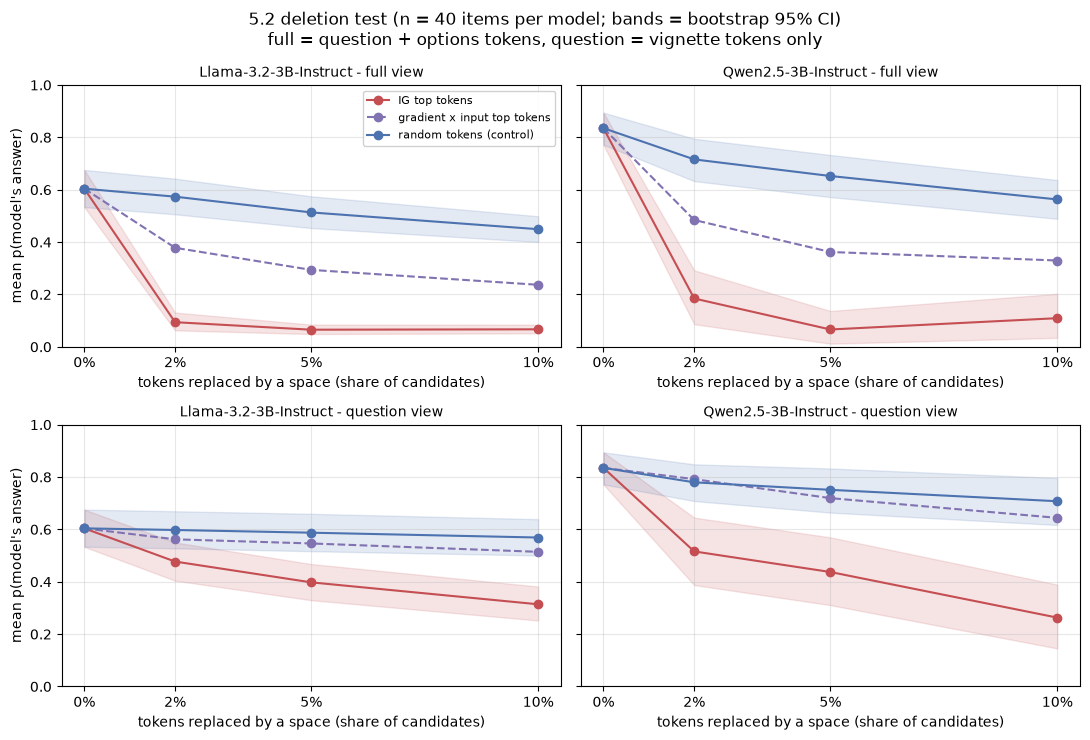

In [12]:
# Cell 11: figure - deletion curves: p(answer) after removing the top-k attributed tokens vs k random tokens
FRACTIONS = sorted(DEL["fraction"].unique())
STYLE = {"ig": ("#C44E52", "-", "IG top tokens"), "gxi": ("#8172B2", "--", "gradient x input top tokens"),
         "random": ("#4C72B0", "-", "random tokens (control)")}
fig, axes = plt.subplots(2, len(MODELS), figsize=(5.5 * len(MODELS), 7.5), sharey=True)
for col, (key, model_id) in enumerate(MODELS.items()):
    p0 = np.array([RECS[key][i]["p_answer"] for i in sorted(EXPECTED_ROWS)])
    for row, view in enumerate(("full", "question")):
        ax = axes[row, col]
        g = DEL[(DEL["model"] == model_id) & (DEL["view"] == view)]
        for series in ("ig", "gxi", "random"):
            color, ls, label = STYLE[series]
            means, los, his = [p0.mean()], [bootstrap_mean_ci(p0)[0]], [bootstrap_mean_ci(p0)[1]]
            for frac in FRACTIONS:
                s = g[(g["fraction"] == frac) & (g["method"] == ("ig" if series == "random" else series))]
                after = s["p_answer"] - (s["random_drop"] if series == "random" else s["top_drop"])
                lo, hi = bootstrap_mean_ci(after)
                means.append(after.mean())
                los.append(lo)
                his.append(hi)
            x = [0] + [100 * f for f in FRACTIONS]
            ax.plot(x, means, ls, marker="o", color=color, label=label)
            if series != "gxi":
                ax.fill_between(x, los, his, color=color, alpha=0.15)
        ax.set_xticks(x, [f"{v:g}%" for v in x])
        ax.set_ylim(0, 1)
        ax.set_title(f"{model_id.split('/')[-1]} - {view} view", fontsize=10)
        ax.set_xlabel("tokens replaced by a space (share of candidates)")
        if col == 0:
            ax.set_ylabel("mean p(model's answer)")
        ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=8, loc="upper right", framealpha=0.9)
fig.suptitle("5.2 deletion test (n = 40 items per model; bands = bootstrap 95% CI)\n"
             "full = question + options tokens, question = vignette tokens only")
fig.tight_layout()
fig.savefig(OUT_DIR / "fig_deletion_curves.png", dpi=200, bbox_inches="tight")
plt.show()

In [13]:
# Cell 12: the three cases - default = first candidate of each category; edit CASES to pick others from the
# shortlist above. Both models' numbers are saved for each chosen item so the contrast can be discussed.
def first(cat: str) -> tuple[str, int]:
    sub = CANDIDATES[CANDIDATES["category"] == cat]
    assert len(sub), f"no candidate for {cat}"
    return sub.iloc[0]["model_key"], int(sub.iloc[0]["row_index"])


CASES = {cat: first(cat) for cat in RULES}   # e.g. CASES["useful"] = ("qwen", 12)
print("chosen cases:", CASES)

case_rows = []
for cat, (key, i) in CASES.items():
    for other in MODELS:
        row = ITEMS[(ITEMS["model_key"] == other) & (ITEMS["row_index"] == i)].iloc[0].to_dict()
        case_rows.append({"category": cat, "case_model": key, "shown_model": other, **row})
CASE_TABLE = pd.DataFrame(case_rows)
CASE_TABLE.to_csv(OUT_DIR / "cases.csv", index=False)
CASE_TABLE[["category", "case_model", "shown_model", "row_index", "gold", "answer", "p_answer", "full_gap", "full_flip",
            "question_gap", "question_flip_10pct", "top1_token", "option_share", "evidence_overlap_full",
            "evidence_chance_full", "top_words_question"]].round(3)

chosen cases: {'useful': ('llama', 24), 'surprising': ('llama', 23), 'misleading': ('llama', 35)}


,category,case_model,shown_model,row_index,gold,answer,p_answer,full_gap,full_flip,question_gap,question_flip_10pct,top1_token,option_share,evidence_overlap_full,evidence_chance_full,top_words_question
0,useful,llama,llama,24,H,H,0.973,0.863,True,0.846,True,malignant,0.638,0.444,0.154,"rigidity, rigidity., haloperidol,, muscle, 160..."
1,useful,llama,qwen,24,H,G,0.727,-0.408,False,0.163,True,H,0.546,0.389,0.187,"lithium,, hypothyroidism., levothyroxine., psy..."
2,surprising,llama,llama,23,D,E,0.407,0.337,True,0.175,True,E,0.484,0.125,0.134,"A, behavior., 40-year-old, behavior?, medicati..."
3,surprising,llama,qwen,23,D,D,0.856,0.636,True,0.222,False,val,0.505,0.500,0.317,"Which, Mental, bipolar, 40-year-old, appropria..."
4,misleading,llama,llama,35,A,E,0.675,0.518,True,0.315,True,pir,0.450,0.050,0.108,"28-year-old, sexually, A, addition, Previous, ..."
5,misleading,llama,qwen,35,A,B,0.898,0.379,True,0.797,True,az,0.558,0.350,0.098,"disturbances,, restlessness,, with, On, 28-yea..."


In [15]:
# Cell 13: figure - word highlights for each case (red = pushed towards the model's answer, blue = against)
# The saved tokens leave out whitespace-only tokens, so word breaks and line breaks are recovered by aligning the
# tokens with the user message the model saw (stored in the Part A baseline record).
USER_MSG = {key: {r["row_index"]: r["prompt"][1]["content"]
                  for r in map(json.loads, (BASELINE_DIR / f"{key}_core.jsonl").read_text(encoding="utf-8").splitlines())
                  if r["row_index"] in EXPECTED_ROWS}
            for key in MODELS}


def case_words(rec: dict, user_text: str) -> list[list]:
    """Words [text, summed IG score, starts_new_line] of the question + options, text taken from the user message."""
    cursor = len("Question:\n")
    words = []
    for tok, score in zip(rec["tokens"]["text"], rec["tokens"]["ig"]):
        piece = tok.strip()
        found = user_text.find(piece, cursor) if piece and "�" not in piece else -1
        if found == -1 or found - cursor > 3:   # a character split over several tokens: keep the score only
            if words:
                words[-1][1] += score
            continue
        chunk = user_text[cursor:found + len(piece)]
        cursor = found + len(piece)
        lead = chunk[:len(chunk) - len(chunk.lstrip())]
        if not words or lead:
            words.append([chunk.strip(), score, "\n" in lead])
        else:
            words[-1][0] += chunk
            words[-1][1] += score
    shown = " ".join(w for w, *_ in words).split()
    expected = user_text[len("Question:\n"):user_text.rindex("\n\nValid answer keys")].split()
    # the last option's final punctuation can share a token with the following line break (outside the span)
    assert shown[:-1] == expected[:-1] and expected[-1].startswith(shown[-1]), \
        f"row {rec['row_index']}: case text does not match the user message"
    return words


def light(rgba, strength: float = 0.45):
    """Blend a colour towards white so black text on it stays readable (strength 1 = full colour)."""
    return tuple(1 - strength * (1 - ch) for ch in rgba[:3])


def word_colour(score: float, cmap, norm):
    """Colour for one word: the darkest 15% at each end of the colour map is skipped, then lightened."""
    v = float(norm(np.clip(score, norm.vmin, norm.vmax)))
    return light(cmap(0.5 + (v - 0.5) * 0.75))


def draw_case(cat: str, key: str, i: int):
    rec, item = RECS[key][i], ITEMS[(ITEMS["model_key"] == key) & (ITEMS["row_index"] == i)].iloc[0]
    words = case_words(rec, USER_MSG[key][i])
    vmax = float(np.percentile(np.abs([s for _, s, _ in words]), 95)) or 1.0   # labels saturate, the rest stay visible
    cmap, norm = plt.get_cmap("RdBu_r"), TwoSlopeNorm(vcenter=0.0, vmin=-vmax, vmax=vmax)
    W, margin, lh, fs = 11.0, 0.3, 0.24, 8.5
    n_lines = sum(nl for *_, nl in words) + sum(len(w) + 1 for w, *_ in words) * 0.068 / (W - 2 * margin) + 4
    H = 1.6 + n_lines * lh + 0.25 * (2 + len(textwrap.wrap(rec["evidence"] or "", 150)))
    fig = plt.figure(figsize=(W, H))
    renderer = fig.canvas.get_renderer()
    # Layout is computed in inches but placed in figure fractions: bbox_inches="tight" shifts figure
    # coordinates when cropping, but not inch (dpi_scale_trans) coordinates.
    def at(x_in: float, y_in: float) -> tuple[float, float]:
        return x_in / W, y_in / H
    title = (f"{cat.capitalize()} case: {MODELS[key].split('/')[-1]}, row {i}. Correct answer {rec['gold']}; "
             f"the model answered {rec['answer']} (p = {rec['p_answer']:.2f}).\n"
             f"How to read: red = the word pushed the model towards its answer, blue = it pushed away; "
             f"darker = stronger.\n"
             f"Deleting the top {HEADLINE_FRACTION:.0%} words lowers p(answer) {item['full_gap']:.2f} more than "
             f"deleting random words. The evidence cites {item['evidence_overlap_full']:.2f} of the top words "
             f"(chance {item['evidence_chance_full']:.2f}).")
    title = "\n".join(textwrap.fill(line, 150) for line in title.split("\n"))
    fig.text(*at(margin, H - 0.2), title, transform=fig.transFigure, fontsize=9, va="top", ha="left")
    x, y = margin, H - 1.0
    for w, s, new_line in words:
        if new_line and x > margin:
            x, y = margin, y - lh
        txt = fig.text(*at(x, y), w, transform=fig.transFigure, fontsize=fs, va="top", ha="left",
                       bbox=dict(boxstyle="square,pad=0.12", facecolor=word_colour(s, cmap, norm),
                                 edgecolor="none"))
        width = txt.get_window_extent(renderer=renderer).width / fig.dpi
        if x + width > W - margin and x > margin:
            x, y = margin, y - lh
            txt.set_position(at(x, y))
        x += width + 0.05
    y -= 2 * lh
    fig.text(*at(margin, y), "model's evidence: " + "\n".join(textwrap.wrap(rec["evidence"] or "", 150)),
             transform=fig.transFigure, fontsize=fs, va="top", ha="left", style="italic")
    fig.savefig(OUT_DIR / f"fig_case_{cat}.png", dpi=200, bbox_inches="tight")
    plt.show()


for cat, (key, i) in CASES.items():
    draw_case(cat, key, i)

<Figure size 1100x760.828 with 0 Axes>

<Figure size 1100x672.665 with 0 Axes>

<Figure size 1100x786.72 with 0 Axes>